# Homework 3: Digital Twin & One-Step-Ahead Prediction
## Connecting the Model to Real Weslaco & TCEQ Meteorological Data

Dataset shape after preprocessing: (726, 6)


,datetime,wind,rh,pm25,pm25_in
0,2024-06-16 00:00:00,2.06,52.40,10.13,4.38
1,2024-06-16 01:00:00,1.74,54.57,10.50,4.38
2,2024-06-16 02:00:00,1.16,56.20,11.09,4.31
3,2024-06-16 03:00:00,1.65,57.57,11.28,4.33
4,2024-06-16 04:00:00,0.67,58.61,10.58,4.38


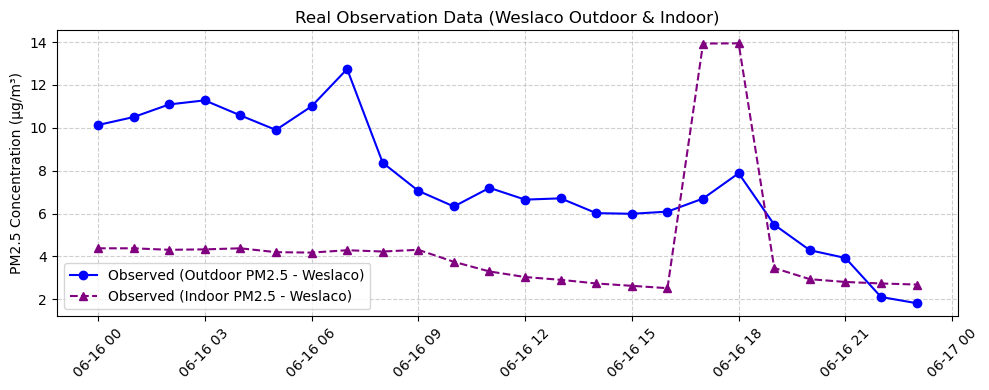

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load datasets directly from Mendeley public direct download links
weslaco_csv="../data/Home1_Weslaco_Indoor_Outdoor_updated.csv"
wind_csv="../data/TCEQ_CAMSdata_WindRose.csv"

df_w = pd.read_csv(weslaco_csv, low_memory=False)
df_wind = pd.read_csv(wind_csv, low_memory=False)


# Extract 1-hour Indoor, Outdoor, and Wind data
indoor_1h = df_w.iloc[1:, 18:23].dropna(how='all').copy()
indoor_1h.columns = ['datetime', 'T_in', 'rh_in', 'raw_pm25_in', 'pm25_in']

outdoor_1h = df_w.iloc[1:, 26:31].dropna(how='all').copy()
outdoor_1h.columns = ['datetime', 'T_out', 'rh', 'raw_pm25_out', 'pm25']

wind_1h = df_wind.iloc[1:, 5:8].dropna(how='all').copy()
wind_1h.columns = ['datetime', 'wind_dir', 'wind']

# Convert datetime and numeric types
for d in [indoor_1h, outdoor_1h, wind_1h]:
    d['datetime'] = pd.to_datetime(d['datetime'].astype(str).str.strip())
    for col in d.columns:
        if col != 'datetime':
            d[col] = pd.to_numeric(d[col], errors='coerce')

# Merge datasets on datetime
df = outdoor_1h[['datetime', 'rh', 'pm25']].merge(
    indoor_1h[['datetime', 'rh_in', 'pm25_in']], on='datetime', how='inner'
).merge(
    wind_1h[['datetime', 'wind']], on='datetime', how='inner'
)

# Preprocess data: remove missing values and duplicates
df = df.dropna().drop_duplicates(subset=['datetime'], keep='first').sort_values('datetime').reset_index(drop=True)
print(f"Dataset shape after preprocessing: {df.shape}")

# Select 24-hour window
df_day = df[:24].copy()
display(df_day[['datetime', 'wind', 'rh', 'pm25', 'pm25_in']].head())

# Plot observed outdoor and indoor PM2.5
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25'], label='Observed (Outdoor PM2.5 - Weslaco)', color='blue', marker='o')
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Observed (Indoor PM2.5 - Weslaco)', color='purple', marker='^', linestyle='--')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Real Observation Data (Weslaco Outdoor & Indoor)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6);
plt.tight_layout(); plt.show()

## Task 2: Simulation & Synchronization (One-Step-Ahead Prediction)

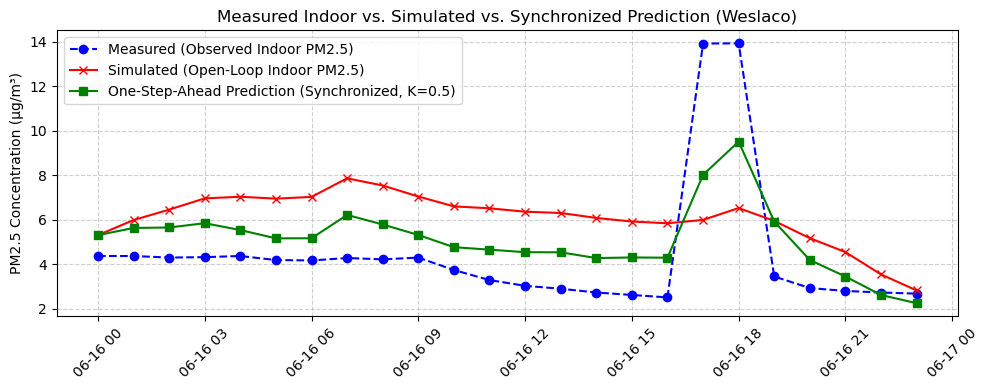

In [14]:
# Advanced Indoor AQ Simulation (Open-Loop)
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001):
    delta_t = 1
    PM_in_list = [data['pm25_in'].iloc[0]]
    for i in range(len(data)):
        prev = PM_in_list[-1]
        out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        change = delta_t * ((k_base + c_w * v) * (out - prev) - (c_h * h) * prev)
        PM_in_list.append(max(0, prev + change))
    return PM_in_list[1:]

# Synchronized Digital Twin Model (One-Step-Ahead Prediction using real indoor measurements)
def simulate_synchronized_aq(data, K=0.5, k_base=0.1, c_w=0.05, c_h=0.001):
    delta_t = 1
    C_sim = data['pm25_in'].iloc[0]
    predictions = []
    for i in range(len(data)):
        C_obs = data['pm25_in'].iloc[i]
        # Correct state with observation
        C_updated = C_sim + K * (C_obs - C_sim)
        # Predict next step
        out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        change = delta_t * ((k_base + c_w * v) * (out - C_updated) - (c_h * h) * C_updated)
        C_sim = max(0, C_updated + change)
        predictions.append(C_sim)
    return predictions

simulated_pm25 = simulate_advanced_indoor_aq(df_day)
predicted_pm25 = simulate_synchronized_aq(df_day, K=0.5)

# Compare Measured Indoor, Open-Loop Simulation, and Synchronized Prediction
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Measured (Observed Indoor PM2.5)', linestyle='--', color='blue', marker='o')
plt.plot(df_day['datetime'], simulated_pm25, label='Simulated (Open-Loop Indoor PM2.5)', color='red', marker='x')
plt.plot(df_day['datetime'], predicted_pm25, label='One-Step-Ahead Prediction (Synchronized, K=0.5)', color='green', marker='s')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Measured Indoor vs. Simulated vs. Synchronized Prediction (Weslaco)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6);
plt.tight_layout(); plt.show()